In [ ]:
import pandas as pd

# NumPy helps with numerical computations
import numpy as np

# Machine Learning Algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression

# Used to split dataset into training and testing data
from sklearn.model_selection import train_test_split

# Used to evaluate classification models
from sklearn.metrics import accuracy_score, confusion_matrix

# Converts text columns into numerical values
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv("/Dataset 2.csv")
print(df)

     UserID  Age  Gender SubscriptionType  WatchHoursPerWeek  DevicesUsed  \
0      1001   22  Female            Basic                 23            5   
1      1002   55    Male            Basic                  9            4   
2      1003   49    Male            Basic                  8            3   
3      1004   39  Female          Premium                 19            5   
4      1005   38  Female          Premium                 23            5   
..      ...  ...     ...              ...                ...          ...   
745    1746   35    Male          Premium                 13            5   
746    1747   43  Female              VIP                 11            3   
747    1748   33  Female          Premium                 19            4   
748    1749   33    Male            Basic                 20            4   
749    1750   25  Female          Premium                 12            3   

    FavoriteGenre  AdClicks  MonthlySpend SubscriptionRenewed  
0          

Tasks

Part A: Dataset Understanding

Q1.
Load the dataset and display the first five records.

Q2.
Determine the number of rows and columns in the dataset.

Q3.
Display all column names.

Q4.
Identify numerical and categorical features.

Q5.
Check whether the dataset contains missing values.

In [ ]:
print(df.head())

   UserID  Age  Gender SubscriptionType  WatchHoursPerWeek  DevicesUsed  \
0    1001   22  Female            Basic                 23            5   
1    1002   55    Male            Basic                  9            4   
2    1003   49    Male            Basic                  8            3   
3    1004   39  Female          Premium                 19            5   
4    1005   38  Female          Premium                 23            5   

  FavoriteGenre  AdClicks  MonthlySpend SubscriptionRenewed  
0        Comedy        13           353                  No  
1         Drama        14           317                 Yes  
2        Comedy        16           309                  No  
3         Drama        45           833                 Yes  
4        Sci-Fi        24           804                 Yes  


In [ ]:
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 750
Number of columns: 10


In [ ]:
print('\nColumns:')
print(df.columns)


Columns:
Index(['UserID', 'Age', 'Gender', 'SubscriptionType', 'WatchHoursPerWeek',
       'DevicesUsed', 'FavoriteGenre', 'AdClicks', 'MonthlySpend',
       'SubscriptionRenewed'],
      dtype='object')


In [ ]:
print('\nData Types')
print(df.dtypes)


Data Types
UserID                  int64
Age                     int64
Gender                 object
SubscriptionType       object
WatchHoursPerWeek       int64
DevicesUsed             int64
FavoriteGenre          object
AdClicks                int64
MonthlySpend            int64
SubscriptionRenewed    object
dtype: object


In [ ]:
print(df.isnull())

     UserID    Age  Gender  SubscriptionType  WatchHoursPerWeek  DevicesUsed  \
0     False  False   False             False              False        False   
1     False  False   False             False              False        False   
2     False  False   False             False              False        False   
3     False  False   False             False              False        False   
4     False  False   False             False              False        False   
..      ...    ...     ...               ...                ...          ...   
745   False  False   False             False              False        False   
746   False  False   False             False              False        False   
747   False  False   False             False              False        False   
748   False  False   False             False              False        False   
749   False  False   False             False              False        False   

     FavoriteGenre  AdClicks  MonthlySp

Part B: Exploratory Data Analysis

Q6.
Calculate the average age of users.

Q7.
Determine the average watch hours per week.

Q8.
Find the average monthly spending of users.

Q9.
Count the number of users in each subscription category.

Q10.
Determine the percentage of users who renewed their subscriptions.

In [ ]:
average_age = df["Age"].mean()
print("Average Age of Users:", round(average_age, 2))

Average Age of Users: 41.82


In [ ]:
average_watch_hours = df["WatchHoursPerWeek"].mean()
print("Average Watch Hours Per Week:", round(average_watch_hours, 2))

Average Watch Hours Per Week: 14.24


In [ ]:
average_spending = df["MonthlySpend"].mean()
print("Average Monthly Spending (₹):", round(average_spending, 2))

Average Monthly Spending (₹): 689.91


In [ ]:
subscription_counts = df["SubscriptionType"].value_counts()

print("Users in Each Subscription Category:")
print(subscription_counts)

Users in Each Subscription Category:
SubscriptionType
Basic      342
Premium    279
VIP        129
Name: count, dtype: int64


In [ ]:
renewed_users = (df["SubscriptionRenewed"] == "Yes").sum()
total_users = len(df)
renewal_percentage = (renewed_users / total_users) * 100

print("Percentage of Users Who Renewed:",
      round(renewal_percentage, 2), "%")

Percentage of Users Who Renewed: 46.27 %


Part C: Data Preparation

Q11.
Convert categorical features into numerical form.

Q12.
Define the feature set (X) and target variable (y) for subscription renewal prediction.

Q13.
Split the dataset into training and testing sets.

In [ ]:
le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])
df["SubscriptionType"] = le.fit_transform(df["SubscriptionType"])
df["FavoriteGenre"] = le.fit_transform(df["FavoriteGenre"])
df["SubscriptionRenewed"] = le.fit_transform(df["SubscriptionRenewed"])

print(df.head())

   UserID  Age  Gender  SubscriptionType  WatchHoursPerWeek  DevicesUsed  \
0    1001   22       0                 0                 23            5   
1    1002   55       1                 0                  9            4   
2    1003   49       1                 0                  8            3   
3    1004   39       0                 1                 19            5   
4    1005   38       0                 1                 23            5   

   FavoriteGenre  AdClicks  MonthlySpend  SubscriptionRenewed  
0              1        13           353                    0  
1              2        14           317                    1  
2              1        16           309                    0  
3              2        45           833                    1  
4              5        24           804                    1  


In [ ]:
X = df.drop(["UserID", "SubscriptionRenewed"], axis=1)

y = df["SubscriptionRenewed"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (750, 8)
Target Shape: (750,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (600, 8)
Testing Data Shape: (150, 8)


Part D: Decision Tree Classification

Q14.
Train a Decision Tree model to predict whether a user will renew their subscription.

Q15.
Evaluate the model using accuracy.

Q16.
Generate and interpret the confusion matrix.

Accuracy: 56.0 %

Confusion Matrix:
[[48 34]
 [32 36]]


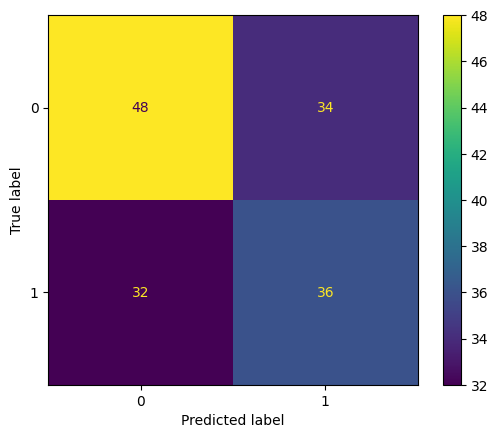

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict
y_pred = dt_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

Part E: K-Nearest Neighbors (KNN)

Q17.
Train a KNN classifier with K = 5.

Q18.
Compare the accuracy of KNN with the Decision Tree model.

In [ ]:
# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create KNN model with K = 5
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [ ]:
from sklearn.metrics import accuracy_score

# KNN Accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Decision Tree Accuracy
dt_accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

Decision Tree Accuracy: 56.0 %
KNN Accuracy: 54.0 %


In [ ]:
if knn_accuracy > dt_accuracy:
    print("KNN performs better than Decision Tree.")
elif knn_accuracy < dt_accuracy:
    print("Decision Tree performs better than KNN.")
else:
    print("Both models have the same accuracy.")

Decision Tree performs better than KNN.


Part F: Linear Regression

Q19.
Train a Linear Regression model to predict monthly spending.

Q20.
Predict the monthly spending for a new user and interpret the result.

In [ ]:
X_reg = df.drop(["UserID", "MonthlySpend", "SubscriptionRenewed"], axis=1)
y_reg = df["MonthlySpend"]

In [ ]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

In [ ]:
lr_model = LinearRegression()

lr_model.fit(X_train_reg, y_train_reg)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [ ]:
new_user = [[22, 0, 0, 23, 5, 1, 13]]

predicted_spend = lr_model.predict(new_user)

print("Predicted Monthly Spending: ₹", round(predicted_spend[0], 2))

Predicted Monthly Spending: ₹ 383.81


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
